# Testing models: naive baselines, Ridge, Lasso and gradient boosting

Day-ahead price forecasting for NO1. All models are trained on 2019–2023 and evaluated on the 2024 validation set.
The 2025 test set is not used here; it is kept untouched until the final models are chosen.

**Metrics** (all in EUR/MWh except R² and rMAE):
- **MAE** (mean absolute error): the average size of the error, ignoring its sign. MAE = 10 means the forecast is off by 10 EUR/MWh on average.
- **RMSE** (root mean squared error): like MAE, but large errors count more, so it is sensitive to price spikes.
- **RSS** (residual sum of squares): the sum of all squared errors, in (EUR/MWh)². It grows with the number of hours, so only compare RSS between models on the same set, not between train and validation.
- **R²**: share of the variation in the price explained by the model (1 = perfect, 0 = no better than always predicting the average).
- **rMAE**: MAE divided by the MAE of the daily naive baseline. Below 1 means better than the baseline.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_utils import (
    TARGET, load_data, split_data, results_table,
    plot_time_series, plot_parity, plot_residuals, plot_error_by_group,
)
from Baseline.baseline import naive_predictions
from model_utils import FEATURES
from Linear_models.linear_models import build_linear, tune_alpha, coefficients
from Gradient_boosting.gradient_boosting import build_gradient_boosting, tune_gradient_boosting, feature_importance

## Load and split the data

In [9]:
df = load_data()
print(df.head())
train, val, test = split_data(df)

for name, data in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {len(data):>6} hours   {data['timestamp'].min()}  to  {data['timestamp'].max()}")

                  timestamp  day_ahead_price  load_forecast  actual_load  \
0 2019-01-31 23:00:00+00:00            51.31        5785.04      5834.83   
1 2019-02-01 00:00:00+00:00            50.47        5641.08      5705.04   
2 2019-02-01 01:00:00+00:00            50.03        5459.89      5508.91   
3 2019-02-01 02:00:00+00:00            50.10        5473.32      5538.59   
4 2019-02-01 03:00:00+00:00            50.72        5524.60      5589.15   

   wind_forecast  hydro_run_of_river  hydro_reservoir  hour  day_of_week  \
0          66.83              585.48          1296.87     0            4   
1          78.01              580.90          1291.26     1            4   
2          75.99              579.13          1293.26     2            4   
3          73.48              577.29          1291.11     3            4   
4          72.09              577.19          1289.16     4            4   

   month  ...  hydro_reservoir_lag_24h  hydro_reservoir_lag_168h  \
0      2  ...     

## Baseline models

- **daily_naive**: the price at the same hour the day before (lag 24h)
- **weekly_naive**: the price at the same hour one week before (lag 168h)
- **hybrid_naive** (Lago et al., 2021): weekly naive for Monday, Saturday and Sunday, daily naive otherwise

In [10]:
baseline_train = naive_predictions(train)
baseline_val = naive_predictions(val)

print("Train")
display(results_table(train[TARGET], baseline_train).round(3))
print("Validation")
display(results_table(val[TARGET], baseline_val).round(3))

Train


,MAE,RMSE,RSS,R2,rMAE
model,,,,,
daily_naive,12.125,28.203,3.202932e+07,0.893,1.000
weekly_naive,20.952,44.859,8.103308e+07,0.730,1.728
hybrid_naive,15.202,34.745,4.861321e+07,0.838,1.254


Validation


,MAE,RMSE,RSS,R2,rMAE
model,,,,,
daily_naive,13.029,26.185,5.715823e+06,0.397,1.000
weekly_naive,19.189,35.202,1.033005e+07,-0.090,1.473
hybrid_naive,13.654,25.333,5.349723e+06,0.436,1.048


## Regularized linear models: Ridge and Lasso

Both are linear regression with a penalty on the coefficients, with strength `alpha` (larger `alpha` gives a simpler model):
- **Ridge** (L2 penalty, sum of squared coefficients): shrinks all coefficients towards zero.
- **Lasso** (L1 penalty, sum of absolute coefficients): can set coefficients exactly to zero, so it also selects features.

`alpha` is chosen by fitting on the training set and comparing MAE on the validation set.
Note: scikit-learn scales the two penalties differently, so the alpha values of Ridge and Lasso are not comparable with each other.

In [11]:
alpha_grid = {
    "ridge": np.logspace(-2, 4, 13),
    "lasso": np.logspace(-3, 1, 13),
}

tuning = {model: tune_alpha(train, val, alphas, model) for model, alphas in alpha_grid.items()}

for model, table in tuning.items():
    print(model)
    display(table.round(3))

C:\Users\alexa\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.956e+06, tolerance: 2.996e+04
  model = cd_fast.enet_coordinate_descent(


ridge


,alpha,train_MAE,val_MAE,nonzero_coefs
0,0.010,12.990,12.837,60
1,0.032,12.990,12.837,60
2,0.100,12.990,12.837,60
3,0.316,12.990,12.837,60
4,1.000,12.990,12.837,60
5,3.162,12.988,12.835,60
6,10.000,12.984,12.830,60
7,31.623,12.973,12.817,60
8,100.000,12.944,12.790,60
9,316.228,12.899,12.758,60


lasso


,alpha,train_MAE,val_MAE,nonzero_coefs
0,0.001,12.985,12.826,58
1,0.002,12.978,12.817,54
2,0.005,12.965,12.798,52
3,0.010,12.938,12.769,51
4,0.022,12.886,12.722,42
5,0.046,12.799,12.655,31
6,0.100,12.637,12.586,26
7,0.215,12.419,12.615,21
8,0.464,12.247,12.661,13
9,1.000,12.323,12.822,7


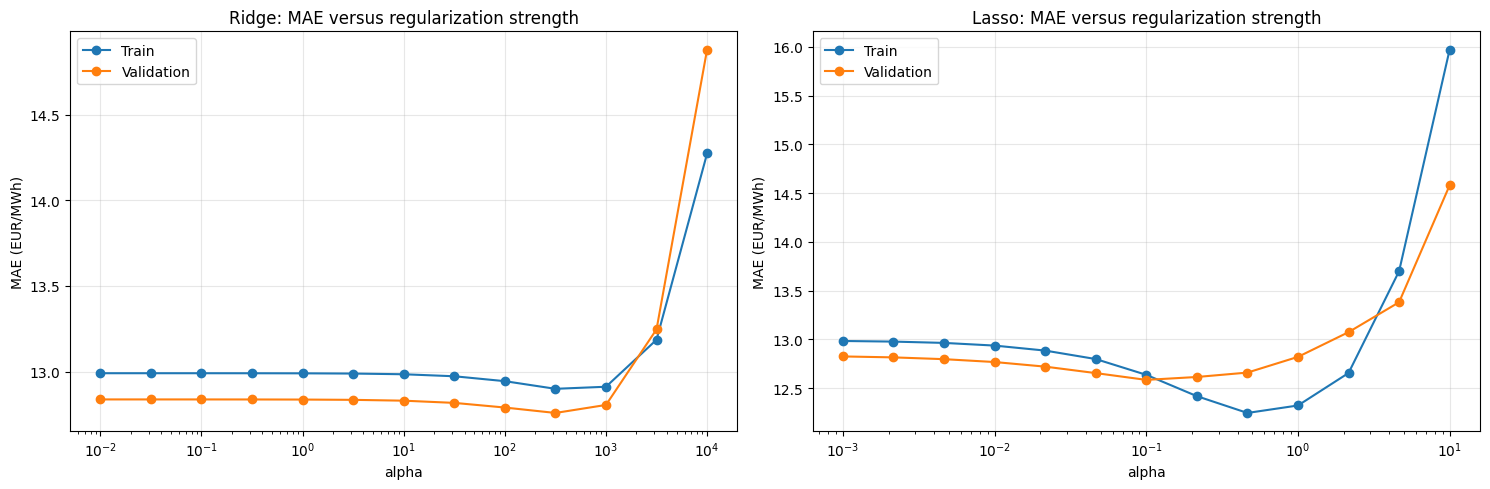

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (model, table) in zip(axes, tuning.items()):
    ax.semilogx(table["alpha"], table["train_MAE"], marker="o", label="Train")
    ax.semilogx(table["alpha"], table["val_MAE"], marker="o", label="Validation")
    ax.set_title(f"{model.capitalize()}: MAE versus regularization strength")
    ax.set_xlabel("alpha")
    ax.set_ylabel("MAE (EUR/MWh)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [13]:
best_alpha = {model: table.loc[table["val_MAE"].idxmin(), "alpha"] for model, table in tuning.items()}
print("Best alpha:", best_alpha)

linear_models = {
    model: build_linear(model, alpha).fit(train[FEATURES], train[TARGET])
    for model, alpha in best_alpha.items()
}

Best alpha: {'ridge': np.float64(316.22776601683796), 'lasso': np.float64(0.1)}


## Gradient boosting

Gradient boosting builds many small decision trees one after another, where each new tree corrects the errors of the trees before it.
We use scikit-learn's `HistGradientBoostingRegressor` (the same idea as LightGBM). Trees need no scaling or one-hot encoding.

Hyperparameters tuned on the validation set:
- `loss`: `squared_error` (like Ridge/Lasso) or `absolute_error` (minimises MAE directly, less sensitive to spikes)
- `learning_rate`: how much each new tree is allowed to correct
- `max_iter`: number of trees
- `max_leaf_nodes`: size (complexity) of each tree
- `min_samples_leaf`: minimum number of hours in each leaf, larger values give smoother predictions

This cell takes a few minutes to run.

In [14]:
gb_grid = {
    "loss": ["squared_error", "absolute_error"],
    "learning_rate": [0.03, 0.1],
    "max_iter": [200, 300, 500],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [20],
}

gb_tuning = tune_gradient_boosting(train, val, gb_grid)
gb_tuning.round(3)

,learning_rate,loss,max_iter,max_leaf_nodes,min_samples_leaf,train_MAE,val_MAE
0,0.03,absolute_error,500,31,20,8.115,11.663
1,0.03,absolute_error,300,31,20,9.040,11.674
2,0.03,absolute_error,300,63,20,7.748,11.708
3,0.03,absolute_error,200,63,20,8.598,11.734
4,0.03,squared_error,200,31,20,8.255,11.765
5,0.03,absolute_error,200,31,20,9.606,11.812
6,0.03,squared_error,300,31,20,7.442,11.820
7,0.03,absolute_error,500,63,20,6.881,11.838
8,0.03,squared_error,200,63,20,6.838,11.840
9,0.10,absolute_error,200,31,20,7.671,11.882


In [15]:
gb_params = gb_tuning.drop(columns=["train_MAE", "val_MAE"]).iloc[0].to_dict()
gb_params = {key: int(value) if key in ["max_iter", "max_leaf_nodes", "min_samples_leaf"] else value for key, value in gb_params.items()}
print("Best hyperparameters:", gb_params)

gradient_boosting = build_gradient_boosting(**gb_params).fit(train[FEATURES], train[TARGET])

Best hyperparameters: {'learning_rate': 0.03, 'loss': 'absolute_error', 'max_iter': 500, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}


## Comparison: all models

In [16]:
pred_train = baseline_train[["daily_naive", "hybrid_naive"]].copy()
pred_val = baseline_val[["daily_naive", "hybrid_naive"]].copy()

for model, fitted in {**linear_models, "gradient_boosting": gradient_boosting}.items():
    pred_train[model] = fitted.predict(train[FEATURES])
    pred_val[model] = fitted.predict(val[FEATURES])

comparison = pd.concat({
    "train": results_table(train[TARGET], pred_train),
    "validation": results_table(val[TARGET], pred_val),
})
comparison.round(3)

MAE    RMSE           RSS     R2   rMAE
           model                                                        
train      daily_naive        12.125  28.203  3.202932e+07  0.893  1.000
           hybrid_naive       15.202  34.745  4.861321e+07  0.838  1.254
           ridge              12.899  25.617  2.642501e+07  0.912  1.064
           lasso              12.637  25.661  2.651598e+07  0.911  1.042
           gradient_boosting   8.115  20.255  1.652173e+07  0.945  0.669
validation daily_naive        13.029  26.185  5.715823e+06  0.397  1.000
           hybrid_naive       13.654  25.333  5.349723e+06  0.436  1.048
           ridge              12.758  23.149  4.467191e+06  0.529  0.979
           lasso              12.586  23.230  4.498277e+06  0.526  0.966
           gradient_boosting  11.663  22.493  4.217336e+06  0.555  0.895

The plots below show the daily naive baseline and the three ML models (the hybrid naive is left out to keep them readable).

In [17]:
plot_models = ["daily_naive", "ridge", "lasso", "gradient_boosting"]

### Actual vs predicted price: two weeks in winter and two weeks in summer (validation set)

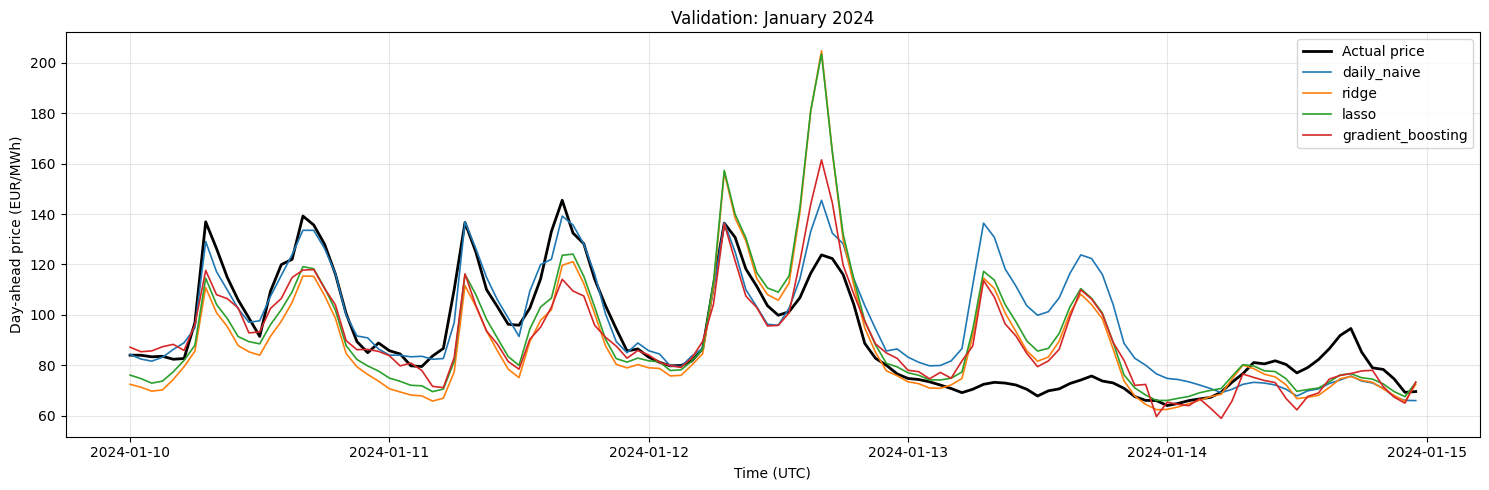

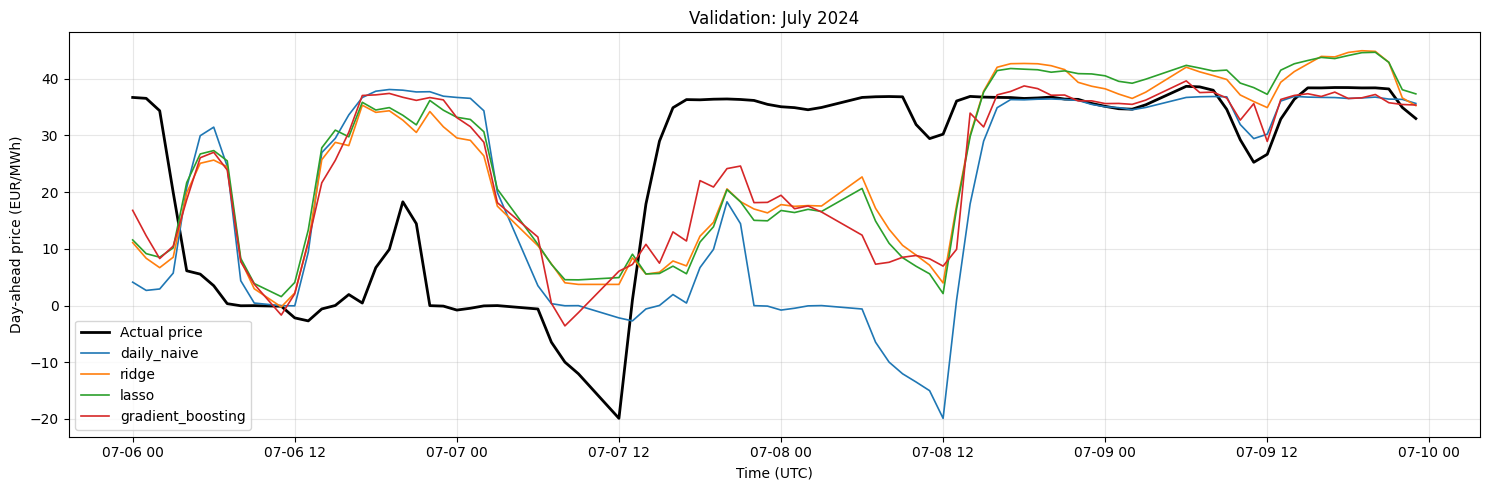

In [18]:
plot_time_series(val, pred_val[plot_models], "2024-01-10", "2024-01-15", "Validation: January 2024")
plot_time_series(val, pred_val[plot_models], "2024-07-06", "2024-07-10", "Validation: July 2024")

### Daily average price over the whole validation year

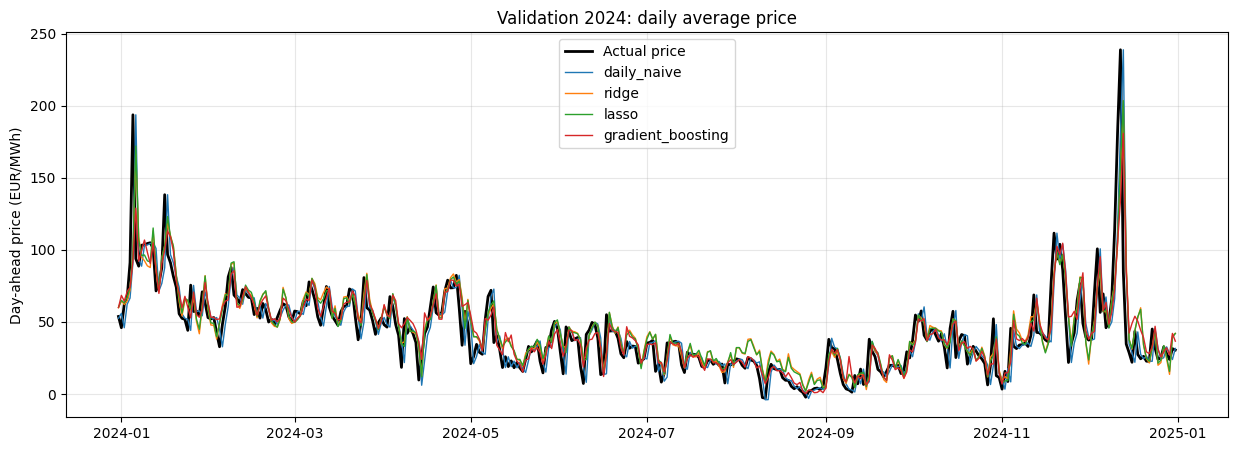

In [19]:
daily = pd.concat([val[["timestamp", TARGET]], pred_val[plot_models]], axis=1).set_index("timestamp").resample("D").mean()

plt.figure(figsize=(15, 5))
plt.plot(daily.index, daily[TARGET], color="black", linewidth=2, label="Actual price")
for model in plot_models:
    plt.plot(daily.index, daily[model], linewidth=1, label=model)
plt.title("Validation 2024: daily average price")
plt.ylabel("Day-ahead price (EUR/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Parity plots (validation set)

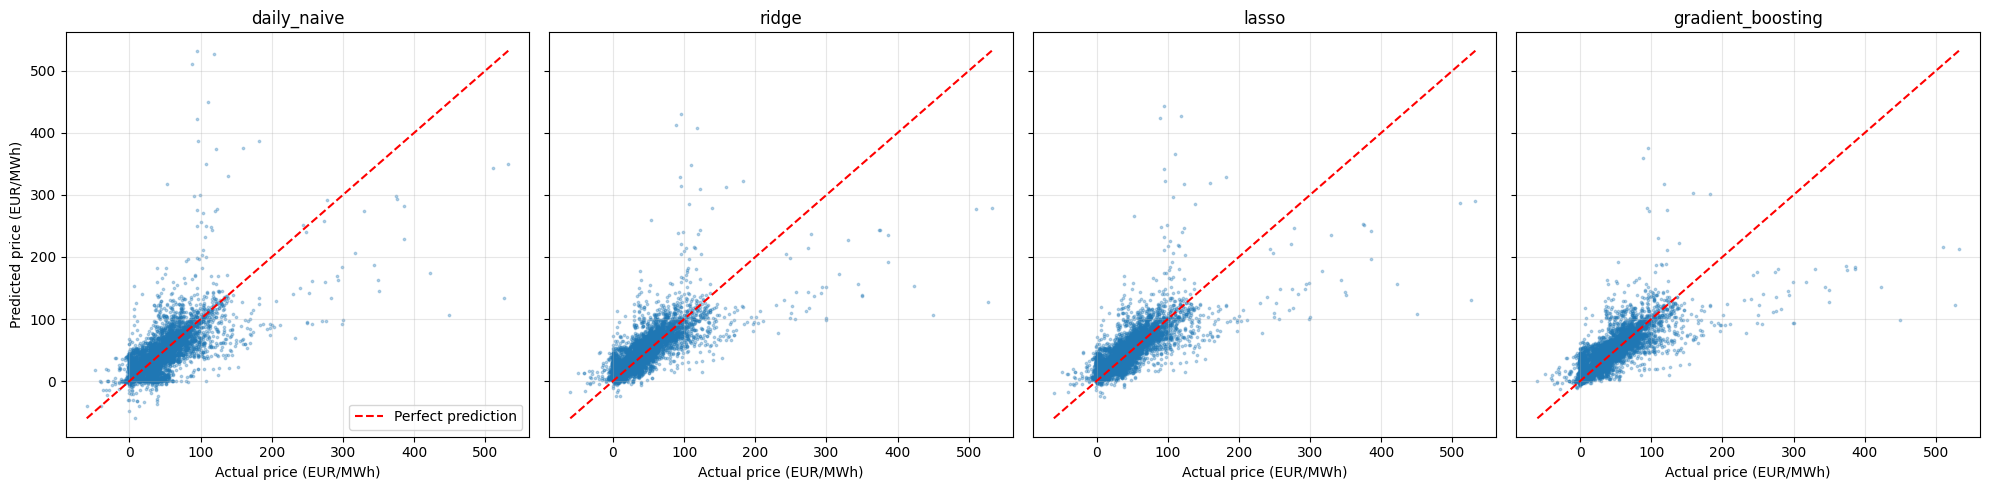

In [20]:
plot_parity(val[TARGET], pred_val[plot_models])

### Residuals (validation set)

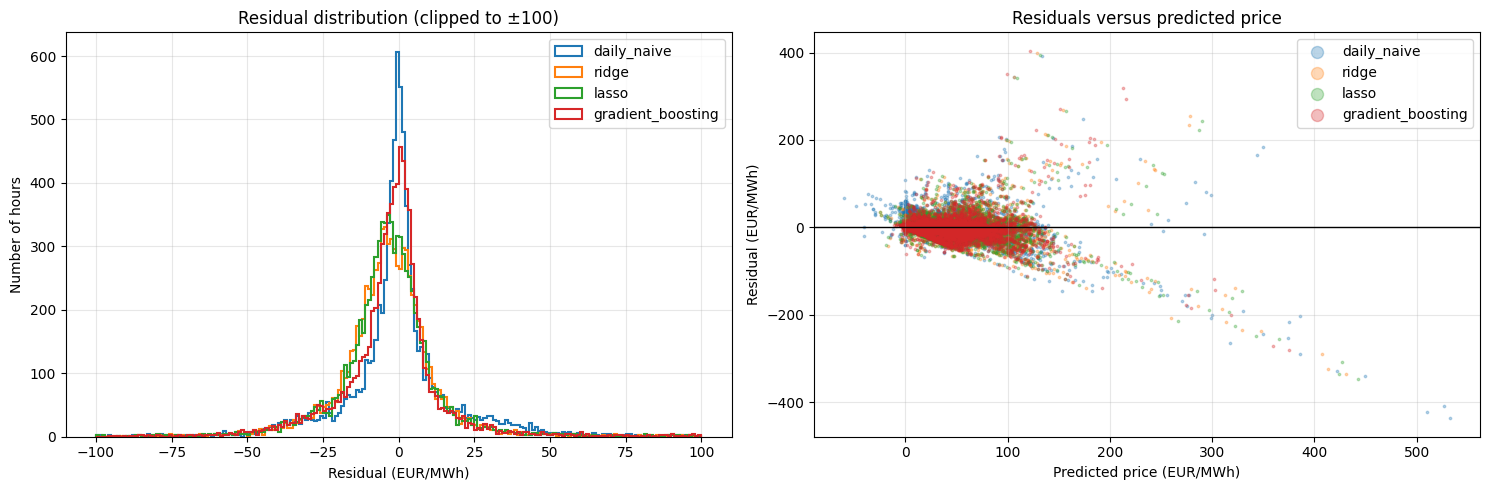

In [21]:
plot_residuals(val[TARGET], pred_val[plot_models])

### When are the errors largest? (validation set)

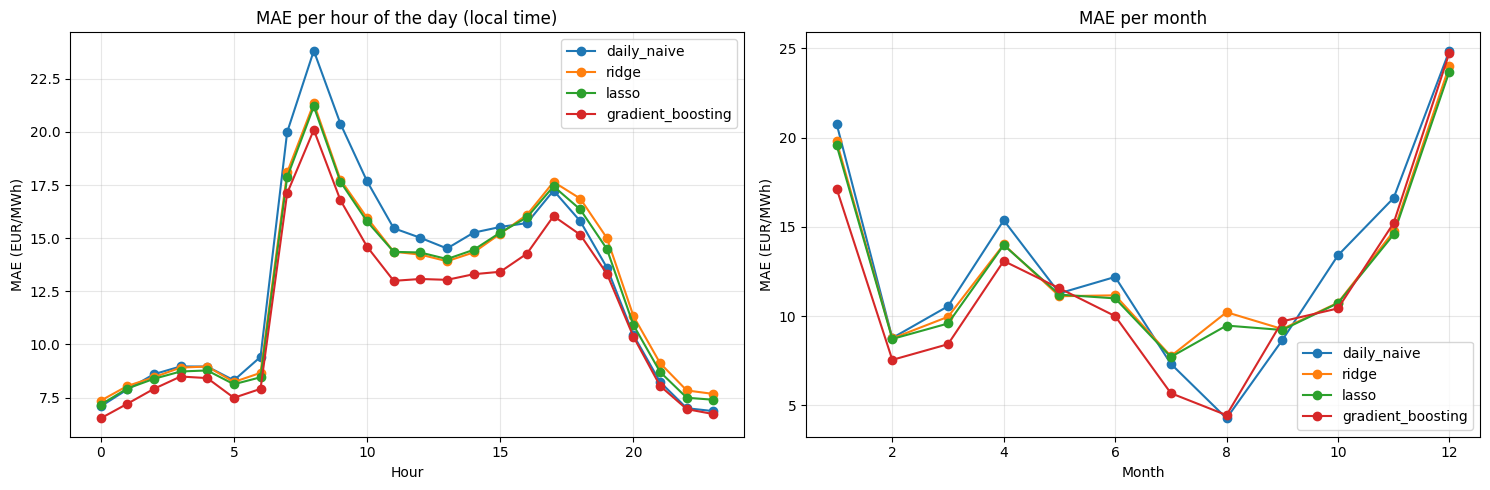

In [22]:
plot_error_by_group(val, pred_val[plot_models])

### Coefficients: Ridge vs Lasso

The numeric features are standardized, so their coefficients are comparable: the change in price (EUR/MWh) for a one standard deviation change in the feature.
Calendar coefficients are the price difference relative to the first category (hour 0, Monday, January).

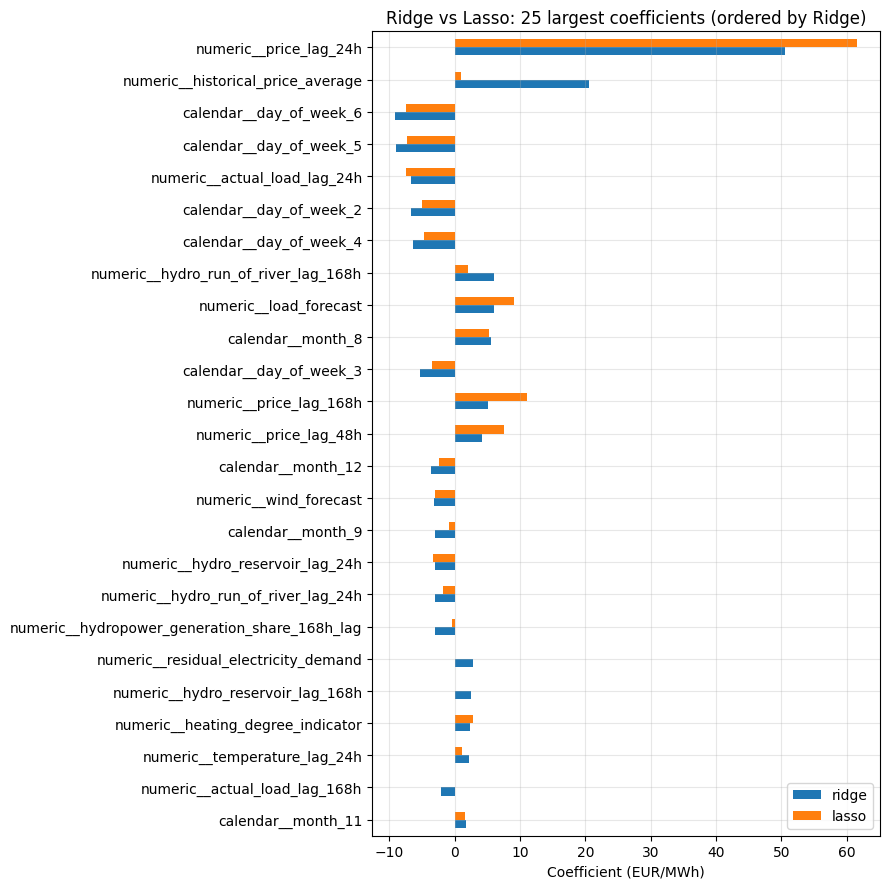

In [23]:
coefs = pd.DataFrame({model: coefficients(fitted) for model, fitted in linear_models.items()})
coefs = coefs.loc[coefs["ridge"].abs().sort_values(ascending=False).index]

coefs.head(25)[::-1].plot.barh(figsize=(9, 9))
plt.title("Ridge vs Lasso: 25 largest coefficients (ordered by Ridge)")
plt.xlabel("Coefficient (EUR/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
dropped = coefs.index[coefs["lasso"] == 0]
print(f"Lasso keeps {(coefs['lasso'] != 0).sum()} of {len(coefs)} coefficients. Set to zero:")
print(list(dropped))

Lasso keeps 26 of 60 coefficients. Set to zero:
['numeric__residual_electricity_demand', 'numeric__hydro_reservoir_lag_168h', 'numeric__actual_load_lag_168h', 'numeric__mean_temperature_NO1', 'calendar__month_5', 'calendar__month_10', 'calendar__hour_13', 'calendar__hour_15', 'calendar__hour_14', 'calendar__month_7', 'calendar__day_of_week_1', 'calendar__hour_12', 'calendar__hour_16', 'calendar__hour_11', 'calendar__hour_6', 'calendar__hour_21', 'calendar__hour_19', 'calendar__hour_5', 'calendar__hour_20', 'calendar__month_6', 'calendar__hour_22', 'calendar__hour_7', 'calendar__hour_3', 'calendar__hour_17', 'calendar__hour_18', 'calendar__hour_8', 'calendar__hour_23', 'calendar__hour_10', 'calendar__hour_1', 'calendar__hour_9', 'calendar__hour_4', 'calendar__month_2', 'calendar__hour_2', 'calendar__month_4']


### Gradient boosting: feature importance

Permutation importance: how much the validation MAE increases when one feature is randomly shuffled (larger = more important).
Correlated features (e.g. the price lags) share their importance, so each one on its own can look less important than the group.

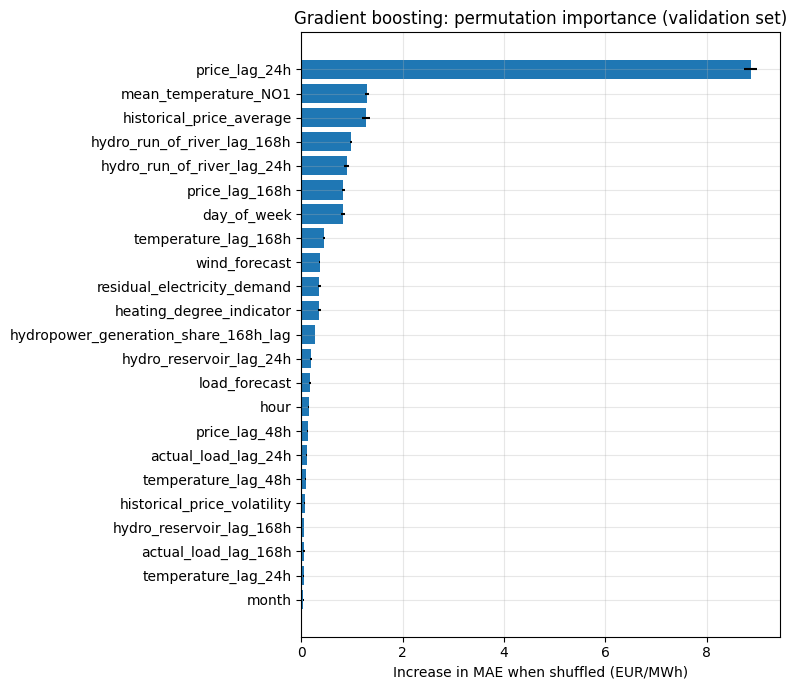

In [25]:
importance = feature_importance(gradient_boosting, val)

plt.figure(figsize=(8, 7))
plt.barh(importance.index[::-1], importance["MAE_increase"][::-1], xerr=importance["std"][::-1])
plt.title("Gradient boosting: permutation importance (validation set)")
plt.xlabel("Increase in MAE when shuffled (EUR/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Shap analysis

Shap analysis can be used to look at the different feature's importance